# Lab 04: Introduction to Matplotlib

## Problem 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")
print(df.head())

   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
numerical = df.select_dtypes(include="number").columns.tolist()
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", numerical)
print("Categorical:", categorical)

Numerical: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


**Interpretation:** Numerical attributes such as Age, Fare, and Pclass are used for line plots, scatter plots, and histograms. Categorical attributes such as Sex and Survived are used for bar and pie charts.

## Problem 2

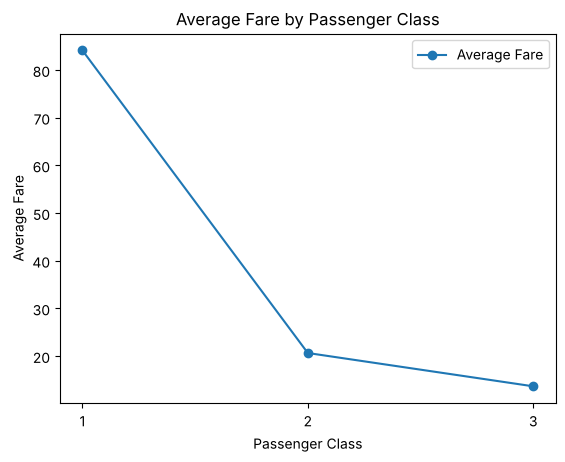

In [4]:
avg_fare = df.groupby("Pclass")["Fare"].mean()

plt.plot(avg_fare.index, avg_fare.values, marker="o", label="Average Fare")
plt.xticks([1, 2, 3])
plt.title("Average Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Fare")
plt.legend()
plt.show()

**Interpretation:** Average fare drops sharply from first class to third class.

## Problem 3

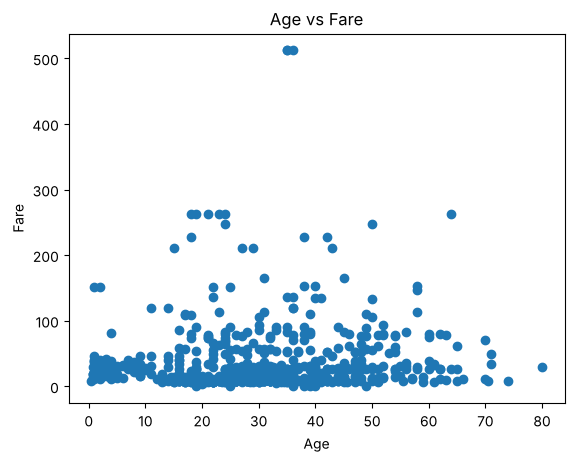

In [5]:
plt.scatter(df["Age"], df["Fare"])
plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

**Interpretation:** There is no strong relationship between age and fare. Most passengers paid low fares, and a few outliers paid very high fares.

## Problem 4

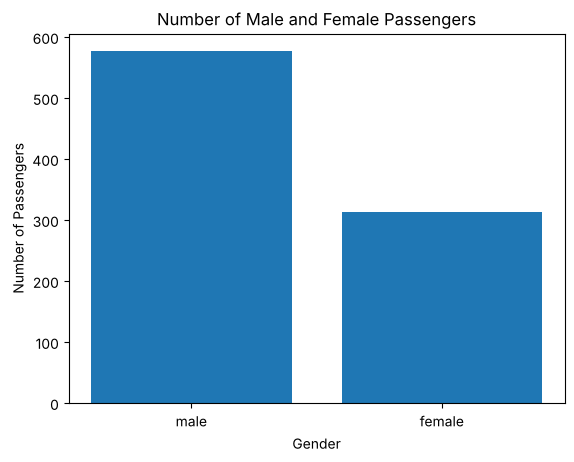

In [6]:
gender_counts = df["Sex"].value_counts()

plt.bar(gender_counts.index, gender_counts.values)
plt.title("Number of Male and Female Passengers")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

**Interpretation:** There are more male passengers than female passengers.

## Problem 5

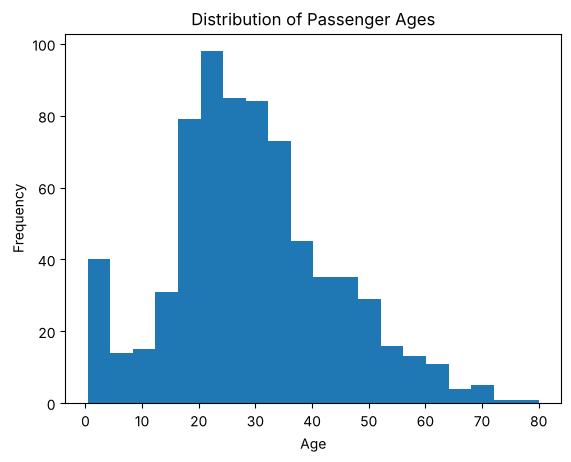

In [7]:
plt.hist(df["Age"].dropna(), bins=20)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Interpretation:** Most passengers are between 20 and 40 years old, with fewer children and older passengers.

## Problem 6

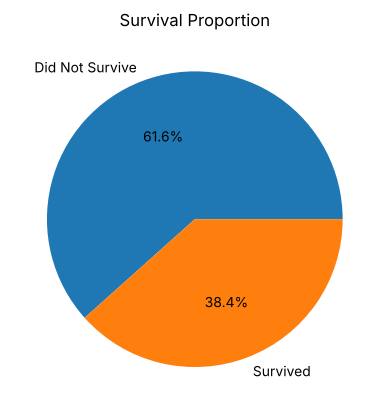

In [8]:
survival_counts = df["Survived"].value_counts().sort_index()

plt.pie(survival_counts.values, labels=["Did Not Survive", "Survived"], autopct="%1.1f%%")
plt.title("Survival Proportion")
plt.show()

**Interpretation:** About 62% of passengers did not survive, and about 38% survived.

## Problem 7

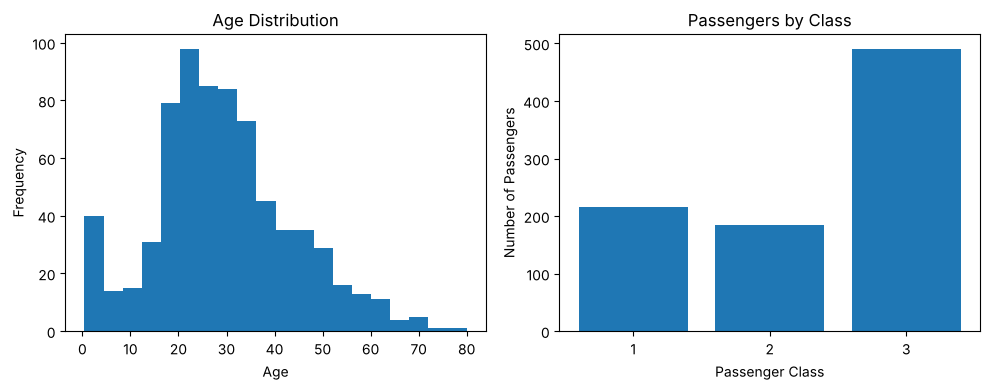

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(df["Age"].dropna(), bins=20)
ax[0].set_title("Age Distribution")
ax[0].set_xlabel("Age")
ax[0].set_ylabel("Frequency")

class_counts = df["Pclass"].value_counts().sort_index()
ax[1].bar(class_counts.index.astype(str), class_counts.values)
ax[1].set_title("Passengers by Class")
ax[1].set_xlabel("Passenger Class")
ax[1].set_ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

**Interpretation:** Most passengers are young adults, and third class has the most passengers.

## Problem 8

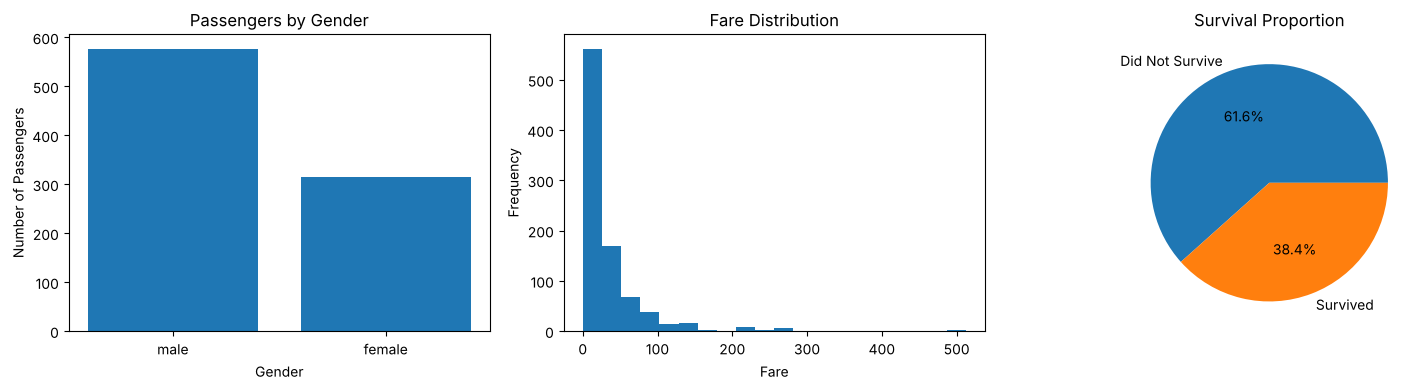

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].bar(gender_counts.index, gender_counts.values)
ax[0].set_title("Passengers by Gender")
ax[0].set_xlabel("Gender")
ax[0].set_ylabel("Number of Passengers")

ax[1].hist(df["Fare"], bins=20)
ax[1].set_title("Fare Distribution")
ax[1].set_xlabel("Fare")
ax[1].set_ylabel("Frequency")

ax[2].pie(survival_counts.values, labels=["Did Not Survive", "Survived"], autopct="%1.1f%%")
ax[2].set_title("Survival Proportion")

plt.tight_layout()
plt.show()

**Interpretation:** Male passengers outnumber female passengers, most fares are low with a few very high values, and fewer than half of the passengers survived.